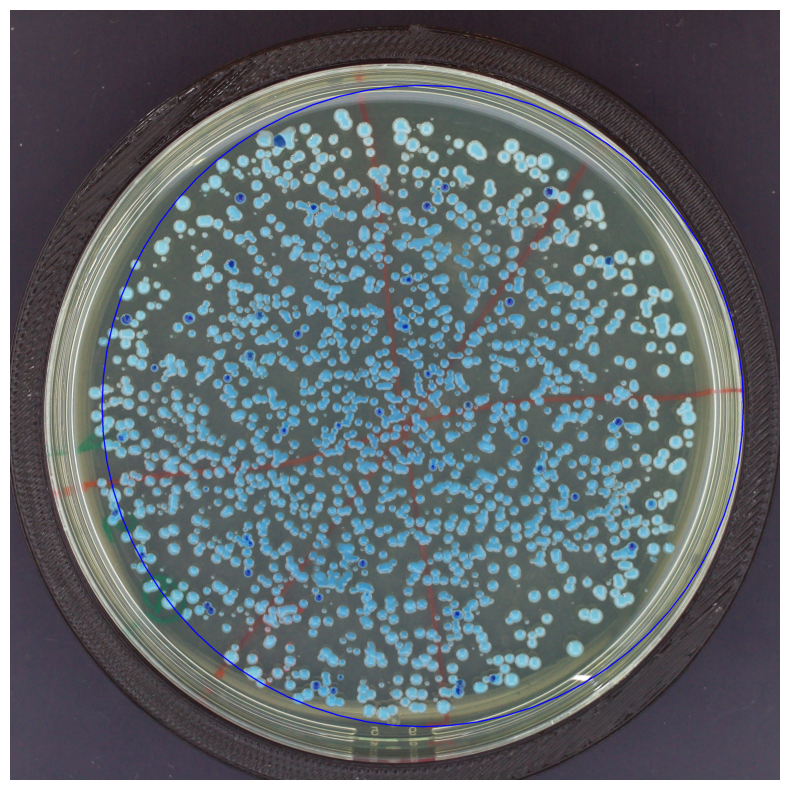

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import Button, VBox, HBox
from IPython.display import display, clear_output
from pathlib import Path

images_path = Path("../data/labeled/images")
masks_path = Path("../data/labeled/circle_masks")

masks_files = [masks_path / f for f in os.listdir(masks_path)]

files = [images_path / f for f in os.listdir(images_path)]

files = [
    f for f in files if f.stem not in [masks_files.stem for masks_files in masks_files]
]

files


# Function to detect circles in an image
def detect_circles(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)

    width, height = img.shape[1], img.shape[0]

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.medianBlur(gray, 5)
    circles = cv2.HoughCircles(
        gray,
        cv2.HOUGH_GRADIENT,
        dp=6,
        minDist=100,
        param1=150,
        param2=10,
        # Circle should be large, but not larger than the image.
        minRadius=round(max(height, width) / 3),
        maxRadius=round(max(height, width) / 2),
    )
    if circles is not None:
        circles = np.uint16(np.around(circles))
    return img, circles


# Function to display an image and circles with interactive buttons
def interactive_circle_validation(image_path):
    img, circles = detect_circles(image_path)
    current_circle_idx = 0

    def on_button_clicked(b):
        nonlocal current_circle_idx
        if b.description == "Yes":
            if circles is not None:
                # Save the circle as a mask
                mask = np.zeros((img.shape[0], img.shape[1]), dtype=np.uint8)
                cv2.circle(
                    mask,
                    (
                        circles[0, current_circle_idx, 0],
                        circles[0, current_circle_idx, 1],
                    ),
                    circles[0, current_circle_idx, 2],
                    (255),
                    thickness=-1,
                )
                image_path_path = Path(image_path)
                mask_filename = (
                    image_path_path.parent.parent
                    / "circle_masks"
                    / (image_path_path.stem + ".png")
                )
                cv2.imwrite(str(mask_filename), mask)
            next_image()
        elif b.description == "No":
            current_circle_idx += 1
            if current_circle_idx < circles.shape[1]:
                display_image_with_circle(current_circle_idx)
            else:
                next_image()

    def display_image_with_circle(idx):
        clear_output(wait=True)
        circle_img = img.copy()
        cv2.circle(
            circle_img,
            (circles[0, idx, 0], circles[0, idx, 1]),
            circles[0, idx, 2],
            (255, 0, 0),
            3,
        )
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(circle_img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()
        display(buttons_box)

    yes_button = Button(description="Yes")
    no_button = Button(description="No")
    yes_button.on_click(on_button_clicked)
    no_button.on_click(on_button_clicked)
    buttons_box = HBox([yes_button, no_button])

    if circles is not None:
        display_image_with_circle(current_circle_idx)
    else:
        next_image()


def next_image():
    if files:
        interactive_circle_validation(str(files.pop(0)))
    else:
        print("No more images.")


# Start processing the images
next_image()